## Figure 2

Representative XAS and XMCD spectra

Repository root: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload

Fixed parameter selection:
  Sl     = 0.7
  SOC2p  = 0.9
  SOC3d  = 1.06

Spectrum-selection summary

Fe
  Directory          : /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/quanty/runs/Fe_d6/spec
  all_spec_files              : 7560
  all_xas_files               : 3780
  all_xmcd_files              : 3780
  selected_xas                : 70
  selected_xmcd               : 70
  skipped_wrong_prefix        : 0
  skipped_fixed_parameters    : 7420
  skipped_missing_parameters  : 0

Co
  Directory          : /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/quanty/runs/Co_d7/spec
  all_

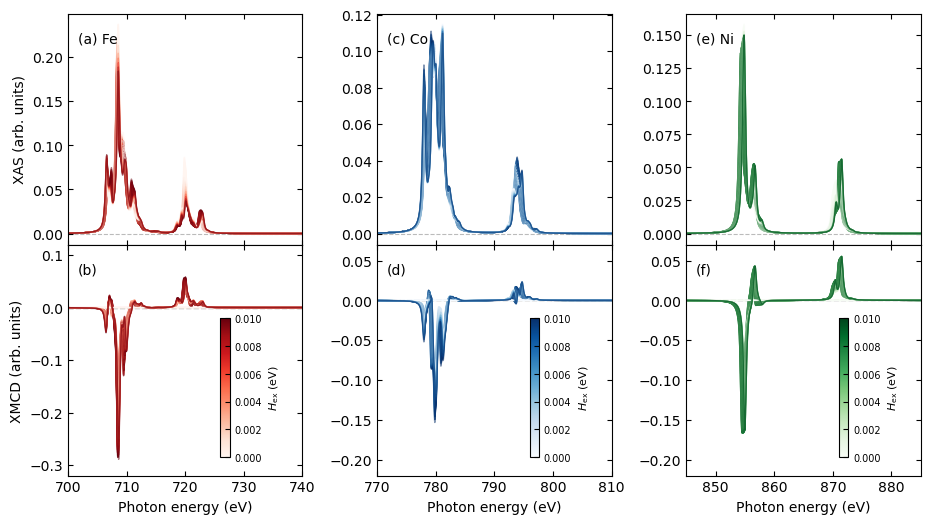


Plotted spectrum counts
Fe: XAS=70, XMCD=70
Co: XAS=70, XMCD=70
Ni: XAS=70, XMCD=70

PNG saved to: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/figures/Figure2_XAS_XMCD_multi_element.png
PDF saved to: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/figures/Figure2_XAS_XMCD_multi_element.pdf


In [9]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# ============================================================
# Settings
# ============================================================

figure_name = "Figure2"

elements = [
    "Fe",
    "Co",
    "Ni",
]

# Fixed calculation parameters used to select spectra.
fixed_parameters = {
    "Sl": 0.70,
    "SOC2p": 0.90,
    "SOC3d": 1.06,
}

parameter_tolerance = 1.0e-10

spectrum_skip_header = 4
spectrum_energy_column = 0
spectrum_intensity_column = 2

output_dpi = 300


# ============================================================
# Repository-root detection
# ============================================================

def find_repository_root(
    start_directory=None,
):
    """
    Find the repository root by searching upward.

    The repository root is identified by the presence of both:

        src/
        configs/
    """

    if start_directory is None:
        current_directory = Path.cwd().resolve()

    else:
        current_directory = (
            Path(
                start_directory
            )
            .expanduser()
            .resolve()
        )

    candidates = [
        current_directory,
        *current_directory.parents,
    ]

    for candidate in candidates:
        if (
            (
                candidate
                / "src"
            ).is_dir()
            and (
                candidate
                / "configs"
            ).is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Repository root could not be found. "
        "Expected directories 'src' and 'configs'."
    )


repository_root = find_repository_root()

quanty_root = (
    repository_root
    / "quanty"
    / "runs"
)

output_directory = (
    repository_root
    / "figures"
)

output_directory.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# Spectrum directories
# ============================================================

directories = {
    "Fe": (
        quanty_root
        / "Fe_d6"
        / "spec"
    ),

    "Co": (
        quanty_root
        / "Co_d7"
        / "spec"
    ),

    "Ni": (
        quanty_root
        / "Ni_d8"
        / "spec"
    ),
}

system_prefixes = {
    "Fe": "Fe_L23_d6__",
    "Co": "Co_L23_d7__",
    "Ni": "Ni_L23_d8__",
}


# ============================================================
# Plot settings
# ============================================================

x_ranges = {
    "Fe": (
        700,
        740,
    ),

    "Co": (
        770,
        810,
    ),

    "Ni": (
        845,
        885,
    ),
}

xmcd_ylim = {
    "Fe": (
        -0.32,
        0.12,
    ),

    "Co": (
        -0.22,
        0.07,
    ),

    "Ni": (
        -0.22,
        0.07,
    ),
}

panel_upper = {
    "Fe": "(a) Fe",
    "Co": "(c) Co",
    "Ni": "(e) Ni",
}

panel_lower = {
    "Fe": "(b)",
    "Co": "(d)",
    "Ni": "(f)",
}

cmap_dict = {
    "Fe": plt.cm.Reds,
    "Co": plt.cm.Blues,
    "Ni": plt.cm.Greens,
}


# ============================================================
# Spectrum loader
# ============================================================

def load_quanty_spec(
    filename,
):
    """
    Load energy and intensity columns from a Quanty spectrum.

    Parameters
    ----------
    filename : str or pathlib.Path
        Quanty spectrum file.

    Returns
    -------
    tuple of numpy.ndarray
        Energy and intensity arrays.
    """

    filename = Path(
        filename
    )

    if not filename.is_file():
        raise FileNotFoundError(
            f"Spectrum file was not found: {filename.name}"
        )

    data = np.genfromtxt(
        filename,
        comments="#",
        skip_header=spectrum_skip_header,
        dtype=np.float64,
    )

    if data.size == 0:
        raise ValueError(
            f"Empty spectrum: {filename.name}"
        )

    if data.ndim == 1:
        data = data.reshape(
            1,
            -1,
        )

    if data.ndim != 2:
        raise ValueError(
            "Spectrum data must be two-dimensional: "
            f"{filename.name}"
        )

    required_column = max(
        spectrum_energy_column,
        spectrum_intensity_column,
    )

    if data.shape[1] <= required_column:
        raise ValueError(
            f"Spectrum {filename.name} contains "
            f"{data.shape[1]} columns, but column "
            f"{required_column} was requested."
        )

    energy = np.asarray(
        data[
            :,
            spectrum_energy_column,
        ],
        dtype=np.float64,
    )

    intensity = np.asarray(
        data[
            :,
            spectrum_intensity_column,
        ],
        dtype=np.float64,
    )

    finite_mask = (
        np.isfinite(
            energy
        )
        & np.isfinite(
            intensity
        )
    )

    energy = energy[
        finite_mask
    ]

    intensity = intensity[
        finite_mask
    ]

    if energy.size == 0:
        raise ValueError(
            "Spectrum contains no finite data points: "
            f"{filename.name}"
        )

    return (
        energy,
        intensity,
    )


# ============================================================
# File-name parameter extraction
# ============================================================

def extract_parameter(
    filename,
    parameter_name,
):
    """
    Extract a floating-point parameter from a file name.

    Supported examples include:

        Sl0.7000
        SOC3d1.0600
        Hex0.100000
        Hex-0.100000
        10Dq1.2000
    """

    filename = Path(
        filename
    ).name

    number_pattern = (
        r"([-+]?"
        r"(?:\d+(?:\.\d*)?|\.\d+)"
        r"(?:[eE][-+]?\d+)?)"
    )

    pattern = (
        re.escape(
            parameter_name
        )
        + number_pattern
    )

    match = re.search(
        pattern,
        filename,
    )

    if match is None:
        return None

    try:
        value = float(
            match.group(
                1
            )
        )

    except ValueError:
        return None

    if not np.isfinite(
        value
    ):
        return None

    return value


def matches_fixed_parameters(
    filename,
):
    """
    Check whether a spectrum matches the fixed parameter values.
    """

    for parameter_name, expected_value in (
        fixed_parameters.items()
    ):
        observed_value = extract_parameter(
            filename,
            parameter_name,
        )

        if observed_value is None:
            return False

        if not np.isclose(
            observed_value,
            expected_value,
            rtol=0.0,
            atol=parameter_tolerance,
        ):
            return False

    return True


# ============================================================
# Collect selected spectra
# ============================================================

records = {}

selection_summary = {}

all_hex_values = []

for element in elements:
    directory = directories[
        element
    ]

    if not directory.is_dir():
        raise NotADirectoryError(
            "Spectrum directory was not found:\n"
            f"{directory}"
        )

    expected_prefix = system_prefixes[
        element
    ]

    all_spec_files = sorted(
        directory.glob(
            "*.spec"
        )
    )

    xas_files = sorted(
        directory.glob(
            "*_k.spec"
        )
    )

    xmcd_files = sorted(
        directory.glob(
            "*_cd.spec"
        )
    )

    selected_xas = []
    selected_xmcd = []

    skipped_wrong_prefix = 0
    skipped_fixed_parameters = 0
    skipped_missing_parameters = 0

    # --------------------------------------------------------
    # XAS
    # --------------------------------------------------------

    for filename in xas_files:
        if not filename.name.startswith(
            expected_prefix
        ):
            skipped_wrong_prefix += 1
            continue

        if not matches_fixed_parameters(
            filename.name
        ):
            skipped_fixed_parameters += 1
            continue

        dq_value = extract_parameter(
            filename.name,
            "10Dq",
        )

        hex_value = extract_parameter(
            filename.name,
            "Hex",
        )

        if (
            dq_value is None
            or hex_value is None
        ):
            skipped_missing_parameters += 1
            continue

        selected_xas.append(
            (
                filename,
                dq_value,
                hex_value,
            )
        )

        all_hex_values.append(
            hex_value
        )

    # --------------------------------------------------------
    # XMCD
    # --------------------------------------------------------

    for filename in xmcd_files:
        if not filename.name.startswith(
            expected_prefix
        ):
            skipped_wrong_prefix += 1
            continue

        if not matches_fixed_parameters(
            filename.name
        ):
            skipped_fixed_parameters += 1
            continue

        dq_value = extract_parameter(
            filename.name,
            "10Dq",
        )

        hex_value = extract_parameter(
            filename.name,
            "Hex",
        )

        if (
            dq_value is None
            or hex_value is None
        ):
            skipped_missing_parameters += 1
            continue

        selected_xmcd.append(
            (
                filename,
                dq_value,
                hex_value,
            )
        )

        all_hex_values.append(
            hex_value
        )

    # Sort by 10Dq, then Hex, then file name.
    selected_xas = sorted(
        selected_xas,
        key=lambda record: (
            record[
                1
            ],
            record[
                2
            ],
            record[
                0
            ].name,
        ),
    )

    selected_xmcd = sorted(
        selected_xmcd,
        key=lambda record: (
            record[
                1
            ],
            record[
                2
            ],
            record[
                0
            ].name,
        ),
    )

    records[
        (
            element,
            "XAS",
        )
    ] = selected_xas

    records[
        (
            element,
            "XMCD",
        )
    ] = selected_xmcd

    selection_summary[
        element
    ] = {
        "all_spec_files": int(
            len(
                all_spec_files
            )
        ),

        "all_xas_files": int(
            len(
                xas_files
            )
        ),

        "all_xmcd_files": int(
            len(
                xmcd_files
            )
        ),

        "selected_xas": int(
            len(
                selected_xas
            )
        ),

        "selected_xmcd": int(
            len(
                selected_xmcd
            )
        ),

        "skipped_wrong_prefix": int(
            skipped_wrong_prefix
        ),

        "skipped_fixed_parameters": int(
            skipped_fixed_parameters
        ),

        "skipped_missing_parameters": int(
            skipped_missing_parameters
        ),
    }


# ============================================================
# Selection report
# ============================================================

print(
    "Repository root:",
    repository_root,
)

print()

print(
    "Fixed parameter selection:"
)

for parameter_name, parameter_value in (
    fixed_parameters.items()
):
    print(
        f"  {parameter_name:6s} = "
        f"{parameter_value:.6g}"
    )

print()
print(
    "Spectrum-selection summary"
)

print(
    "=" * 70
)

for element in elements:
    summary = selection_summary[
        element
    ]

    print()
    print(
        element
    )

    print(
        "  Directory          :",
        directories[
            element
        ],
    )

    for key, value in summary.items():
        print(
            f"  {key:28s}: {value}"
        )


# ============================================================
# Validate selected records
# ============================================================

missing_groups = []

for element in elements:
    if not records[
        (
            element,
            "XAS",
        )
    ]:
        missing_groups.append(
            f"{element} XAS"
        )

    if not records[
        (
            element,
            "XMCD",
        )
    ]:
        missing_groups.append(
            f"{element} XMCD"
        )

if missing_groups:
    raise RuntimeError(
        "No spectra matched the requested fixed parameters for: "
        + ", ".join(
            missing_groups
        )
        + ". Check the parameter values available in the file names."
    )

all_hex_values = np.asarray(
    all_hex_values,
    dtype=np.float64,
)

all_hex_values = all_hex_values[
    np.isfinite(
        all_hex_values
    )
]

if all_hex_values.size == 0:
    raise RuntimeError(
        "No finite Hex values were extracted "
        "from the selected files"
    )

hex_min = float(
    np.min(
        all_hex_values
    )
)

hex_max = float(
    np.max(
        all_hex_values
    )
)

if np.isclose(
    hex_min,
    hex_max,
    rtol=0.0,
    atol=0.0,
):
    margin = max(
        1.0e-12,
        abs(
            hex_min
        )
        * 1.0e-6,
    )

    hex_min -= margin
    hex_max += margin

norm = Normalize(
    vmin=hex_min,
    vmax=hex_max,
)

print()
print(
    f"Selected Hex range: {hex_min:.8g} to {hex_max:.8g}"
)


# ============================================================
# Create figure
# ============================================================

figure = plt.figure(
    figsize=(
        11.0,
        6.0,
    )
)

grid = GridSpec(
    2,
    3,
    figure=figure,
    hspace=0.00,
    wspace=0.32,
)

axes = np.empty(
    (
        2,
        3,
    ),
    dtype=object,
)

for row in range(
    2
):
    for column in range(
        3
    ):
        if row == 0:
            axes[
                row,
                column,
            ] = figure.add_subplot(
                grid[
                    row,
                    column,
                ]
            )

        else:
            axes[
                row,
                column,
            ] = figure.add_subplot(
                grid[
                    row,
                    column,
                ],
                sharex=axes[
                    0,
                    column,
                ],
            )


# ============================================================
# Plot XAS and XMCD
# ============================================================

loaded_spectrum_counts = {}

for column, element in enumerate(
    elements
):
    cmap = cmap_dict[
        element
    ]

    xmin, xmax = x_ranges[
        element
    ]

    loaded_xas = 0
    loaded_xmcd = 0

    # --------------------------------------------------------
    # XAS
    # --------------------------------------------------------

    axis = axes[
        0,
        column,
    ]

    for (
        filename,
        dq_value,
        hex_value,
    ) in records[
        (
            element,
            "XAS",
        )
    ]:
        try:
            energy, intensity = load_quanty_spec(
                filename
            )

        except (
            OSError,
            ValueError,
        ) as exception:
            print(
                "Warning: skipped XAS file "
                f"{filename.name}: {exception}"
            )
            continue

        axis.plot(
            energy,
            intensity,
            color=cmap(
                norm(
                    hex_value
                )
            ),
            linewidth=1.0,
            alpha=0.5,
        )

        loaded_xas += 1

    axis.set_xlim(
        xmin,
        xmax,
    )

    axis.set_ylim(
        bottom=0.0,
    )

    ymin, ymax = axis.get_ylim()

    y_span = (
        ymax
        - ymin
    )

    if y_span > 0.0:
        axis.set_ylim(
            ymin
            - 0.05
            * y_span,
            ymax,
        )

    axis.tick_params(
        labelbottom=False
    )

    axis.text(
        0.04,
        0.92,
        panel_upper[
            element
        ],
        transform=axis.transAxes,
        verticalalignment="top",
    )

    # --------------------------------------------------------
    # XMCD
    # --------------------------------------------------------

    axis = axes[
        1,
        column,
    ]

    for (
        filename,
        dq_value,
        hex_value,
    ) in records[
        (
            element,
            "XMCD",
        )
    ]:
        try:
            energy, intensity = load_quanty_spec(
                filename
            )

        except (
            OSError,
            ValueError,
        ) as exception:
            print(
                "Warning: skipped XMCD file "
                f"{filename.name}: {exception}"
            )
            continue

        axis.plot(
            energy,
            intensity,
            color=cmap(
                norm(
                    hex_value
                )
            ),
            linewidth=1.0,
            alpha=0.5,
        )

        loaded_xmcd += 1

    axis.set_xlim(
        xmin,
        xmax,
    )

    axis.set_ylim(
        xmcd_ylim[
            element
        ]
    )

    axis.text(
        0.04,
        0.92,
        panel_lower[
            element
        ],
        transform=axis.transAxes,
        verticalalignment="top",
    )

    loaded_spectrum_counts[
        element
    ] = {
        "XAS": (
            loaded_xas
        ),
        "XMCD": (
            loaded_xmcd
        ),
    }


# ============================================================
# Axis labels
# ============================================================

axes[
    0,
    0,
].set_ylabel(
    "XAS (arb. units)"
)

axes[
    1,
    0,
].set_ylabel(
    "XMCD (arb. units)"
)

for column in range(
    3
):
    axes[
        1,
        column,
    ].set_xlabel(
        "Photon energy (eV)"
    )


# ============================================================
# Axis style
# ============================================================

for row in range(
    2
):
    for column in range(
        3
    ):
        axis = axes[
            row,
            column,
        ]

        if row == 0:
            zero_line_color = (
                "#BBBBBB"
            )

            zero_line_width = (
                0.8
            )

        else:
            zero_line_color = (
                "#999999"
            )

            zero_line_width = (
                1.0
            )

        axis.axhline(
            0.0,
            color=zero_line_color,
            linewidth=zero_line_width,
            linestyle="--",
            zorder=0,
        )

        axis.tick_params(
            direction="in",
            which="both",
            top=True,
            right=True,
        )


# ============================================================
# Color bars
# ============================================================

for column, element in enumerate(
    elements
):
    color_axis = axes[
        1,
        column,
    ]

    scalar_mappable = ScalarMappable(
        norm=norm,
        cmap=cmap_dict[
            element
        ],
    )

    scalar_mappable.set_array(
        []
    )

    colorbar_axis = inset_axes(
        color_axis,
        width="4%",
        height="60%",
        loc="lower right",
        bbox_to_anchor=(
            -0.28,
            0.05,
            1.0,
            1.0,
        ),
        bbox_transform=color_axis.transAxes,
        borderpad=0.5,
    )

    colorbar = figure.colorbar(
        scalar_mappable,
        cax=colorbar_axis,
    )

    colorbar.set_label(
        r"$H_{\mathrm{ex}}$ (eV)",
        fontsize=8,
    )

    colorbar.ax.tick_params(
        direction="in",
        labelsize=7,
    )


# ============================================================
# Validate plotted spectra
# ============================================================

for element in elements:
    counts = loaded_spectrum_counts[
        element
    ]

    if counts[
        "XAS"
    ] == 0:
        raise RuntimeError(
            f"No valid {element} XAS spectra were plotted"
        )

    if counts[
        "XMCD"
    ] == 0:
        raise RuntimeError(
            f"No valid {element} XMCD spectra were plotted"
        )


# ============================================================
# Save
# ============================================================

png_file = (
    output_directory
    / (
        f"{figure_name}_"
        "XAS_XMCD_multi_element.png"
    )
)

pdf_file = (
    output_directory
    / (
        f"{figure_name}_"
        "XAS_XMCD_multi_element.pdf"
    )
)

figure.savefig(
    png_file,
    dpi=output_dpi,
    bbox_inches="tight",
)

figure.savefig(
    pdf_file,
    bbox_inches="tight",
)

plt.show()

plt.close(
    figure
)


# ============================================================
# Final report
# ============================================================

print()
print(
    "Plotted spectrum counts"
)

print(
    "=" * 40
)

for element in elements:
    print(
        f"{element}: "
        f"XAS={loaded_spectrum_counts[element]['XAS']}, "
        f"XMCD={loaded_spectrum_counts[element]['XMCD']}"
    )

print()
print(
    "PNG saved to:",
    png_file,
)

print(
    "PDF saved to:",
    pdf_file,
)